In [45]:
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.ensemble import IsolationForest
from sklearn.metrics import (
    confusion_matrix,
    precision_score,
    recall_score,
    f1_score,
    classification_report,
    ConfusionMatrixDisplay,
    precision_recall_curve,
    average_precision_score,
    roc_auc_score
)

In [2]:
RANDOM_STATE = 42

In [3]:
df = pd.read_csv("creditcard.csv")

In [4]:
df.shape

(284807, 31)

In [5]:
df.head(40)

,Time,V1,V2,V3,V4,V5,V6,V7,V8,V9,...,V21,V22,V23,V24,V25,V26,V27,V28,Amount,Class
0,0.0,-1.359807,-0.072781,2.536347,1.378155,-0.338321,0.462388,0.239599,0.098698,0.363787,...,-0.018307,0.277838,-0.110474,0.066928,0.128539,-0.189115,0.133558,-0.021053,149.62,0
1,0.0,1.191857,0.266151,0.166480,0.448154,0.060018,-0.082361,-0.078803,0.085102,-0.255425,...,-0.225775,-0.638672,0.101288,-0.339846,0.167170,0.125895,-0.008983,0.014724,2.69,0
2,1.0,-1.358354,-1.340163,1.773209,0.379780,-0.503198,1.800499,0.791461,0.247676,-1.514654,...,0.247998,0.771679,0.909412,-0.689281,-0.327642,-0.139097,-0.055353,-0.059752,378.66,0
3,1.0,-0.966272,-0.185226,1.792993,-0.863291,-0.010309,1.247203,0.237609,0.377436,-1.387024,...,-0.108300,0.005274,-0.190321,-1.175575,0.647376,-0.221929,0.062723,0.061458,123.50,0
4,2.0,-1.158233,0.877737,1.548718,0.403034,-0.407193,0.095921,0.592941,-0.270533,0.817739,...,-0.009431,0.798278,-0.137458,0.141267,-0.206010,0.502292,0.219422,0.215153,69.99,0
5,2.0,-0.425966,0.960523,1.141109,-0.168252,0.420987,-0.029728,0.476201,0.260314,-0.568671,...,-0.208254,-0.559825,-0.026398,-0.371427,-0.232794,0.105915,0.253844,0.081080,3.67,0
6,4.0,1.229658,0.141004,0.045371,1.202613,0.191881,0.272708,-0.005159,0.081213,0.464960,...,-0.167716,-0.270710,-0.154104,-0.780055,0.750137,-0.257237,0.034507,0.005168,4.99,0
7,7.0,-0.644269,1.417964,1.074380,-0.492199,0.948934,0.428118,1.120631,-3.807864,0.615375,...,1.943465,-1.015455,0.057504,-0.649709,-0.415267,-0.051634,-1.206921,-1.085339,40.80,0
8,7.0,-0.894286,0.286157,-0.113192,-0.271526,2.669599,3.721818,0.370145,0.851084,-0.392048,...,-0.073425,-0.268092,-0.204233,1.011592,0.373205,-0.384157,0.011747,0.142404,93.20,0
9,9.0,-0.338262,1.119593,1.044367,-0.222187,0.499361,-0.246761,0.651583,0.069539,-0.736727,...,-0.246914,-0.633753,-0.120794,-0.385050,-0.069733,0.094199,0.246219,0.083076,3.68,0


In [6]:
df.tail(10)

,Time,V1,V2,V3,V4,V5,V6,V7,V8,V9,...,V21,V22,V23,V24,V25,V26,V27,V28,Amount,Class
284797,172782.0,-0.241923,0.712247,0.399806,-0.463406,0.244531,-1.343668,0.929369,-0.206210,0.106234,...,-0.228876,-0.514376,0.279598,0.371441,-0.559238,0.113144,0.131507,0.081265,5.49,0
284798,172782.0,0.219529,0.881246,-0.635891,0.960928,-0.152971,-1.014307,0.427126,0.121340,-0.285670,...,0.099936,0.337120,0.251791,0.057688,-1.508368,0.144023,0.181205,0.215243,24.05,0
284799,172783.0,-1.775135,-0.004235,1.189786,0.331096,1.196063,5.519980,-1.518185,2.080825,1.159498,...,0.103302,0.654850,-0.348929,0.745323,0.704545,-0.127579,0.454379,0.130308,79.99,0
284800,172784.0,2.039560,-0.175233,-1.196825,0.234580,-0.008713,-0.726571,0.017050,-0.118228,0.435402,...,-0.268048,-0.717211,0.297930,-0.359769,-0.315610,0.201114,-0.080826,-0.075071,2.68,0
284801,172785.0,0.120316,0.931005,-0.546012,-0.745097,1.130314,-0.235973,0.812722,0.115093,-0.204064,...,-0.314205,-0.808520,0.050343,0.102800,-0.435870,0.124079,0.217940,0.068803,2.69,0
284802,172786.0,-11.881118,10.071785,-9.834783,-2.066656,-5.364473,-2.606837,-4.918215,7.305334,1.914428,...,0.213454,0.111864,1.014480,-0.509348,1.436807,0.250034,0.943651,0.823731,0.77,0
284803,172787.0,-0.732789,-0.055080,2.035030,-0.738589,0.868229,1.058415,0.024330,0.294869,0.584800,...,0.214205,0.924384,0.012463,-1.016226,-0.606624,-0.395255,0.068472,-0.053527,24.79,0
284804,172788.0,1.919565,-0.301254,-3.249640,-0.557828,2.630515,3.031260,-0.296827,0.708417,0.432454,...,0.232045,0.578229,-0.037501,0.640134,0.265745,-0.087371,0.004455,-0.026561,67.88,0
284805,172788.0,-0.240440,0.530483,0.702510,0.689799,-0.377961,0.623708,-0.686180,0.679145,0.392087,...,0.265245,0.800049,-0.163298,0.123205,-0.569159,0.546668,0.108821,0.104533,10.00,0
284806,172792.0,-0.533413,-0.189733,0.703337,-0.506271,-0.012546,-0.649617,1.577006,-0.414650,0.486180,...,0.261057,0.643078,0.376777,0.008797,-0.473649,-0.818267,-0.002415,0.013649,217.00,0


In [7]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 284807 entries, 0 to 284806
Data columns (total 31 columns):
 #   Column  Non-Null Count   Dtype  
---  ------  --------------   -----  
 0   Time    284807 non-null  float64
 1   V1      284807 non-null  float64
 2   V2      284807 non-null  float64
 3   V3      284807 non-null  float64
 4   V4      284807 non-null  float64
 5   V5      284807 non-null  float64
 6   V6      284807 non-null  float64
 7   V7      284807 non-null  float64
 8   V8      284807 non-null  float64
 9   V9      284807 non-null  float64
 10  V10     284807 non-null  float64
 11  V11     284807 non-null  float64
 12  V12     284807 non-null  float64
 13  V13     284807 non-null  float64
 14  V14     284807 non-null  float64
 15  V15     284807 non-null  float64
 16  V16     284807 non-null  float64
 17  V17     284807 non-null  float64
 18  V18     284807 non-null  float64
 19  V19     284807 non-null  float64
 20  V20     284807 non-null  float64
 21  V21     28

In [8]:
df.nunique()

Time      124592
V1        275663
V2        275663
V3        275663
V4        275663
V5        275663
V6        275663
V7        275663
V8        275663
V9        275663
V10       275663
V11       275663
V12       275663
V13       275663
V14       275663
V15       275663
V16       275663
V17       275663
V18       275663
V19       275663
V20       275663
V21       275663
V22       275663
V23       275663
V24       275663
V25       275663
V26       275663
V27       275663
V28       275663
Amount     32767
Class          2
dtype: int64

In [9]:
df.isna().sum()

Time      0
V1        0
V2        0
V3        0
V4        0
V5        0
V6        0
V7        0
V8        0
V9        0
V10       0
V11       0
V12       0
V13       0
V14       0
V15       0
V16       0
V17       0
V18       0
V19       0
V20       0
V21       0
V22       0
V23       0
V24       0
V25       0
V26       0
V27       0
V28       0
Amount    0
Class     0
dtype: int64

In [10]:
print("0's count: ", np.sum(df["Class"] == 0))

0's count:  284315


In [11]:
print("1's count: ", np.sum(df["Class"] == 1))

1's count:  492


In [12]:
X = df.drop("Class", axis=1)
y = df["Class"]

In [13]:
print("Class percentages:")
print(df["Class"].value_counts(normalize=True) * 100)

Class percentages:
Class
0    99.827251
1     0.172749
Name: proportion, dtype: float64


In [14]:
X_train_val, X_test, y_train_val, y_test = train_test_split(X, y, test_size=0.2, random_state=RANDOM_STATE, stratify=y)

In [15]:
X_train, X_val, y_train, y_val = train_test_split(X_train_val, y_train_val, test_size=0.25, random_state=RANDOM_STATE, stratify=y_train_val)

In [16]:
model = IsolationForest(
    n_estimators=100,
    contamination=0.002,
    random_state=RANDOM_STATE,
    n_jobs=-1
)

In [17]:
model.fit(X_train)

,"contamination contamination: 'auto' or float, default='auto'The amount of contamination of the data set, i.e. the proportionof outliers in the data set. Used when fitting to define the thresholdon the scores of the samples.- If 'auto', the threshold is determined as in the original paper.- If float, the contamination should be in the range (0, 0.5]... versionchanged:: 0.22 The default value of ``contamination`` changed from 0.1 to ``'auto'``.",0.002
,"n_jobs n_jobs: int, default=NoneThe number of jobs to run in parallel for :meth:`fit`. ``None`` means 1unless in a :obj:`joblib.parallel_backend` context. ``-1`` means usingall processors. See :term:`Glossary <n_jobs>` for more details.",-1
,"random_state random_state: int, RandomState instance or None, default=NoneControls the pseudo-randomness of the selection of the featureand split values for each branching step and each tree in the forest.Pass an int for reproducible results across multiple function calls.See :term:`Glossary <random_state>`.",42
,"n_estimators n_estimators: int, default=100The number of base estimators in the ensemble.",100
,"max_samples max_samples: ""auto"", int or float, default=""auto""The number of samples to draw from X to train each base estimator.- If int, then draw `max_samples` samples.- If float, then draw `max_samples * X.shape[0]` samples.- If ""auto"", then `max_samples=min(256, n_samples)`.If max_samples is larger than the number of samples provided,all samples will be used for all trees (no sampling).",'auto'
,"max_features max_features: int or float, default=1.0The number of features to draw from X to train each base estimator.- If int, then draw `max_features` features.- If float, then draw `max(1, int(max_features * n_features_in_))` features.Note: using a float number less than 1.0 or integer less than number offeatures will enable feature subsampling and leads to a longer runtime.",1.0
,"bootstrap bootstrap: bool, default=FalseIf True, individual trees are fit on random subsets of the trainingdata sampled with replacement. If False, sampling without replacementis performed.",False
,"verbose verbose: int, default=0Controls the verbosity of the tree building process.",0
,"warm_start warm_start: bool, default=FalseWhen set to ``True``, reuse the solution of the previous call to fitand add more estimators to the ensemble, otherwise, just fit a wholenew forest. See :term:`the Glossary <warm_start>`... versionadded:: 0.21",False
Name,Type,Value
estimator_ estimator_: :class:`~sklearn.tree.ExtraTreeRegressor` instanceThe child estimator template used to create the collection offitted sub-estimators... versionadded:: 1.2 `base_estimator_` was renamed to `estimator_`.,ExtraTreeRegressor,ExtraTreeRegr...ndom_state=42)


In [18]:
y_val_pred = model.predict(X_val)

y_val_pred = np.where(y_val_pred == -1, 1, 0)

In [19]:
print(f"X validation shape: {X_val.shape}")
print(f"y validation shape: {y_val.shape}")


X validation shape: (56962, 30)
y validation shape: (56962,)


In [20]:
unique, counts = np.unique(y_val_pred, return_counts=True)

for cluster, count in zip(unique, counts):
    print(f"Cluster {cluster}: {count} points.")

Cluster 0: 56846 points.
Cluster 1: 116 points.


In [21]:
print("Confusion_matrix: ")
print(confusion_matrix(y_val, y_val_pred, labels=[0, 1]))

Confusion_matrix: 
[[56774    89]
 [   72    27]]


In [22]:
print(f"Precision_score: {precision_score(y_val, y_val_pred)}")
print(f"recall_score: {recall_score(y_val, y_val_pred)}")
print(f"f1_score: {f1_score(y_val, y_val_pred)}")

Precision_score: 0.23275862068965517
recall_score: 0.2727272727272727
f1_score: 0.25116279069767444


In [23]:
contamination_values = [
    0.001,
    0.0017,
    0.003,
    0.005,
    0.01
]

for c in contamination_values:
    model = IsolationForest(
        n_estimators=100,
        contamination=c,
        random_state=RANDOM_STATE,
        n_jobs=-1
    )
    model.fit(X_train)
    model_pred = model.predict(X_val)
    model_pred = np.where(model_pred == -1, 1, 0)
    print(f"\nFor contamination = {c}" )
    print(f"Precision_score: {precision_score(y_val, model_pred)}")
    print(f"recall_score: {recall_score(y_val, model_pred)}")
    print(f"f1_score: {f1_score(y_val, model_pred)}")


For contamination = 0.001
Precision_score: 0.2653061224489796
recall_score: 0.13131313131313133
f1_score: 0.17567567567567569

For contamination = 0.0017
Precision_score: 0.21782178217821782
recall_score: 0.2222222222222222
f1_score: 0.22

For contamination = 0.003
Precision_score: 0.16470588235294117
recall_score: 0.2828282828282828
f1_score: 0.20817843866171004

For contamination = 0.005
Precision_score: 0.12211221122112212
recall_score: 0.37373737373737376
f1_score: 0.18407960199004975

For contamination = 0.01
Precision_score: 0.08849557522123894
recall_score: 0.5050505050505051
f1_score: 0.15060240963855423


In [24]:
model = IsolationForest(
    n_estimators=100,
    contamination=0.002,
    random_state= RANDOM_STATE,
    n_jobs=-1
)

model.fit(X_train_val)

,"contamination contamination: 'auto' or float, default='auto'The amount of contamination of the data set, i.e. the proportionof outliers in the data set. Used when fitting to define the thresholdon the scores of the samples.- If 'auto', the threshold is determined as in the original paper.- If float, the contamination should be in the range (0, 0.5]... versionchanged:: 0.22 The default value of ``contamination`` changed from 0.1 to ``'auto'``.",0.002
,"n_jobs n_jobs: int, default=NoneThe number of jobs to run in parallel for :meth:`fit`. ``None`` means 1unless in a :obj:`joblib.parallel_backend` context. ``-1`` means usingall processors. See :term:`Glossary <n_jobs>` for more details.",-1
,"random_state random_state: int, RandomState instance or None, default=NoneControls the pseudo-randomness of the selection of the featureand split values for each branching step and each tree in the forest.Pass an int for reproducible results across multiple function calls.See :term:`Glossary <random_state>`.",42
,"n_estimators n_estimators: int, default=100The number of base estimators in the ensemble.",100
,"max_samples max_samples: ""auto"", int or float, default=""auto""The number of samples to draw from X to train each base estimator.- If int, then draw `max_samples` samples.- If float, then draw `max_samples * X.shape[0]` samples.- If ""auto"", then `max_samples=min(256, n_samples)`.If max_samples is larger than the number of samples provided,all samples will be used for all trees (no sampling).",'auto'
,"max_features max_features: int or float, default=1.0The number of features to draw from X to train each base estimator.- If int, then draw `max_features` features.- If float, then draw `max(1, int(max_features * n_features_in_))` features.Note: using a float number less than 1.0 or integer less than number offeatures will enable feature subsampling and leads to a longer runtime.",1.0
,"bootstrap bootstrap: bool, default=FalseIf True, individual trees are fit on random subsets of the trainingdata sampled with replacement. If False, sampling without replacementis performed.",False
,"verbose verbose: int, default=0Controls the verbosity of the tree building process.",0
,"warm_start warm_start: bool, default=FalseWhen set to ``True``, reuse the solution of the previous call to fitand add more estimators to the ensemble, otherwise, just fit a wholenew forest. See :term:`the Glossary <warm_start>`... versionadded:: 0.21",False
Name,Type,Value
estimator_ estimator_: :class:`~sklearn.tree.ExtraTreeRegressor` instanceThe child estimator template used to create the collection offitted sub-estimators... versionadded:: 1.2 `base_estimator_` was renamed to `estimator_`.,ExtraTreeRegressor,ExtraTreeRegr...ndom_state=42)


In [25]:
model_pred = model.predict(X_test)
model_pred = np.where(model_pred == -1, 1, 0)
print(f"Precision_score: {precision_score(y_test, model_pred)}")
print(f"recall_score: {recall_score(y_test, model_pred)}")
print(f"f1_score: {f1_score(y_test, model_pred)}")

Precision_score: 0.2786885245901639
recall_score: 0.3469387755102041
f1_score: 0.3090909090909091


In [26]:
print(confusion_matrix(y_test, model_pred, labels=[0, 1]))

[[56776    88]
 [   64    34]]


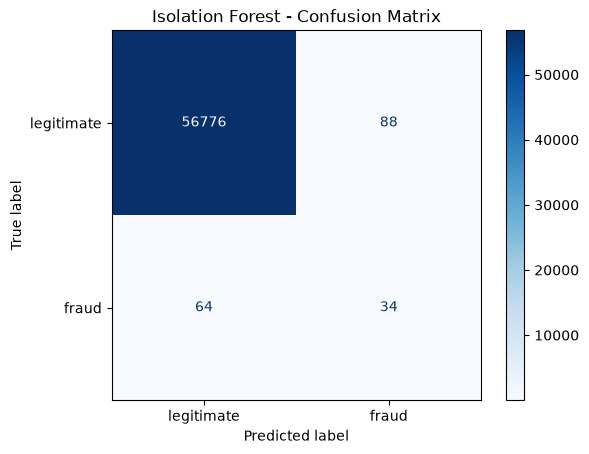

In [27]:
cm = confusion_matrix(y_test, model_pred)

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=["legitimate", "fraud"]
)

disp.plot(cmap="Blues", values_format="d")
plt.title("Isolation Forest - Confusion Matrix")
plt.show()

In [28]:
print(classification_report(
    y_test,
    model_pred,
    target_names=["Legitimate", "Fraud"]
))

              precision    recall  f1-score   support

  Legitimate       1.00      1.00      1.00     56864
       Fraud       0.28      0.35      0.31        98

    accuracy                           1.00     56962
   macro avg       0.64      0.67      0.65     56962
weighted avg       1.00      1.00      1.00     56962



In [29]:
for_model_scores = IsolationForest(
    n_estimators=100,
    contamination="auto",
    random_state=RANDOM_STATE,
    n_jobs=-1
)

for_model_scores.fit(X_train)

,"n_jobs n_jobs: int, default=NoneThe number of jobs to run in parallel for :meth:`fit`. ``None`` means 1unless in a :obj:`joblib.parallel_backend` context. ``-1`` means usingall processors. See :term:`Glossary <n_jobs>` for more details.",-1
,"random_state random_state: int, RandomState instance or None, default=NoneControls the pseudo-randomness of the selection of the featureand split values for each branching step and each tree in the forest.Pass an int for reproducible results across multiple function calls.See :term:`Glossary <random_state>`.",42
,"n_estimators n_estimators: int, default=100The number of base estimators in the ensemble.",100
,"max_samples max_samples: ""auto"", int or float, default=""auto""The number of samples to draw from X to train each base estimator.- If int, then draw `max_samples` samples.- If float, then draw `max_samples * X.shape[0]` samples.- If ""auto"", then `max_samples=min(256, n_samples)`.If max_samples is larger than the number of samples provided,all samples will be used for all trees (no sampling).",'auto'
,"contamination contamination: 'auto' or float, default='auto'The amount of contamination of the data set, i.e. the proportionof outliers in the data set. Used when fitting to define the thresholdon the scores of the samples.- If 'auto', the threshold is determined as in the original paper.- If float, the contamination should be in the range (0, 0.5]... versionchanged:: 0.22 The default value of ``contamination`` changed from 0.1 to ``'auto'``.",'auto'
,"max_features max_features: int or float, default=1.0The number of features to draw from X to train each base estimator.- If int, then draw `max_features` features.- If float, then draw `max(1, int(max_features * n_features_in_))` features.Note: using a float number less than 1.0 or integer less than number offeatures will enable feature subsampling and leads to a longer runtime.",1.0
,"bootstrap bootstrap: bool, default=FalseIf True, individual trees are fit on random subsets of the trainingdata sampled with replacement. If False, sampling without replacementis performed.",False
,"verbose verbose: int, default=0Controls the verbosity of the tree building process.",0
,"warm_start warm_start: bool, default=FalseWhen set to ``True``, reuse the solution of the previous call to fitand add more estimators to the ensemble, otherwise, just fit a wholenew forest. See :term:`the Glossary <warm_start>`... versionadded:: 0.21",False
Name,Type,Value
estimator_ estimator_: :class:`~sklearn.tree.ExtraTreeRegressor` instanceThe child estimator template used to create the collection offitted sub-estimators... versionadded:: 1.2 `base_estimator_` was renamed to `estimator_`.,ExtraTreeRegressor,ExtraTreeRegr...ndom_state=42)


In [30]:
anomoly_scores = -(for_model_scores.score_samples(X_val))

print(anomoly_scores[:30])

[0.43908582 0.39357765 0.36913119 0.43415882 0.37120632 0.40893875
 0.40975834 0.44028857 0.36236711 0.38689054 0.44780128 0.43601634
 0.41346521 0.42602391 0.36045565 0.40548016 0.36862995 0.41217132
 0.41282372 0.4410792  0.39096866 0.38582719 0.53151543 0.37688165
 0.36255663 0.35974267 0.35674132 0.42214626 0.44223996 0.3852536 ]


In [31]:
precision, recall, thresholds = precision_recall_curve(
    y_val,
    anomoly_scores
)

f1_scores = (
    2 * precision[:-1] * recall[:-1]
    / (precision[:-1] + recall[:-1] + 1e-10)
)

In [32]:
best_idx = np.argmax(f1_scores)

best_threshold = thresholds[best_idx]

print("Best Threshold:", best_threshold)
print("Best Precision:", precision[best_idx])
print("Best Recall:", recall[best_idx])
print("Best F1:", f1_scores[best_idx])

Best Threshold: 0.6462498227201251
Best Precision: 0.22764227642276422
Best Recall: 0.2828282828282828
Best F1: 0.25225225220283665


In [33]:
y_val_pred = (anomoly_scores >= best_threshold).astype(int)

In [34]:
test_score = -(for_model_scores.score_samples(X_test))

In [35]:
y_test_pred = (test_score >= best_threshold).astype(int)

In [36]:
print("For test dataset: ")
print(f"Precision score: {precision_score(y_test, y_test_pred)}")
print(f"Recall score: {recall_score(y_test, y_test_pred)}")
print(f"f1 score: {f1_score(y_test, y_test_pred)}")

For test dataset: 
Precision score: 0.2809917355371901
Recall score: 0.3469387755102041
f1 score: 0.3105022831050228


In [37]:
print("For validation dataset: ")
print(f"Precision score: {precision_score(y_val, y_val_pred)}")
print(f"Recall score: {recall_score(y_val, y_val_pred)}")
print(f"f1 score: {f1_score(y_val, y_val_pred)}")

For validation dataset: 
Precision score: 0.22764227642276422
Recall score: 0.2828282828282828
f1 score: 0.25225225225225223


In [39]:
val_ap = average_precision_score(y_val, anomoly_scores)

In [42]:
print(f"Validation Average Precision: {val_ap:.4f}")

Validation Average Precision: 0.1177


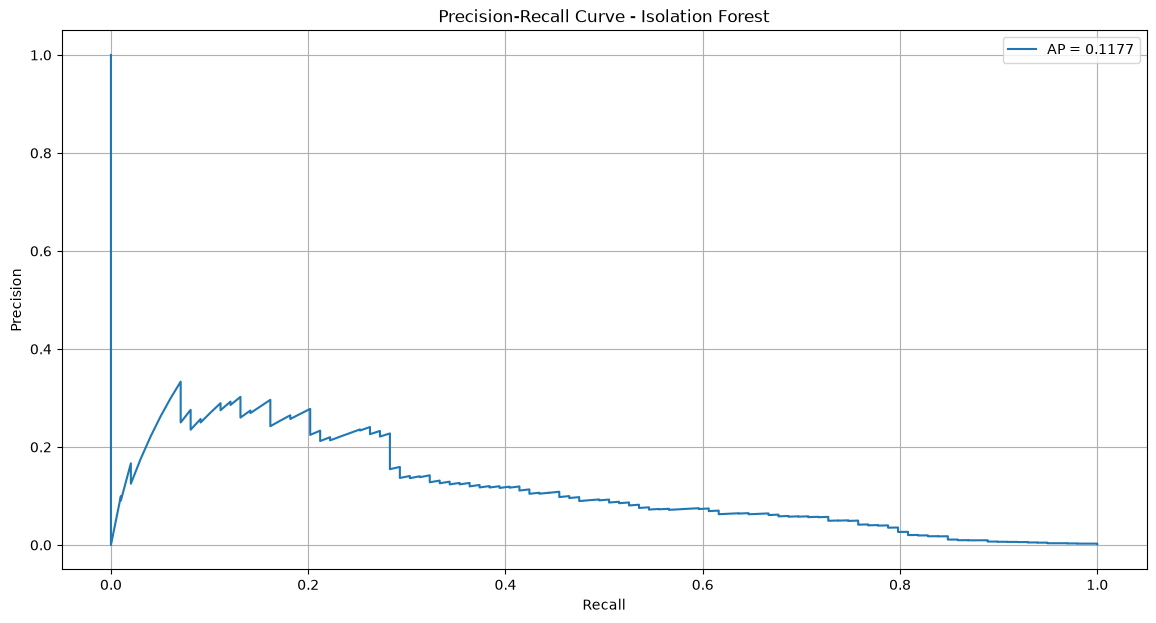

In [43]:
plt.figure(figsize=(14, 7))
plt.plot(recall, precision, label=f"AP = {val_ap:.4f}")
plt.xlabel("Recall")
plt.ylabel("Precision")
plt.title("Precision-Recall Curve - Isolation Forest")
plt.legend()
plt.grid()
plt.show()

In [44]:
test_ap = average_precision_score(y_test, test_score)

print(f"Test Average Precision: {test_ap:.6f}")

Test Average Precision: 0.174285


In [46]:
val_roc_auc = roc_auc_score(y_val, anomoly_scores)

In [50]:
print(f"Val roc_auc score: {val_roc_auc:.4f}")

Val roc_auc score: 0.9398


In [51]:
test_roc_auc = roc_auc_score(y_test, y_test_pred)

In [52]:
print(f"Test roc_auc score: {test_roc_auc:.4f}")

Test roc_auc score: 0.6727


In [53]:
print("Validation: ")
print(y_val.shape)
print(f"\nTest: ")
print(y_test.shape)

Validation: 
(56962,)

Test: 
(56962,)


In [54]:
print("Validation scores:")
print(pd.Series(anomoly_scores).describe())

print("\nTest scores:")
print(pd.Series(test_score).describe())

Validation scores:
count    56962.000000
mean         0.407503
std          0.043222
min          0.345776
25%          0.377853
50%          0.397787
75%          0.425521
max          0.765166
dtype: float64

Test scores:
count    56962.000000
mean         0.407977
std          0.043733
min          0.345897
25%          0.378298
50%          0.398117
75%          0.425429
max          0.766372
dtype: float64


In [55]:
print("Validation scores by class:")
print(pd.Series(anomoly_scores).groupby(
    y_val.reset_index(drop=True)
).mean())

print("\nTest scores by class:")
print(pd.Series(test_score).groupby(
    y_test.reset_index(drop=True)
).mean())

Validation scores by class:
Class
0    0.407217
1    0.571504
dtype: float64

Test scores by class:
Class
0    0.407659
1    0.592533
dtype: float64
